##  t-Test Family

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Generate one-sample, independent and paired samples
np.random.seed(42)

# One-sample: 30 heights, true mean 172, test against 170
heights = np.random.normal(loc=172, scale=6, size=30)

# Independent: class A mean=170 vs class B mean=174, same std=6
class_A = np.random.normal(loc=170, scale=6, size=40)
class_B = np.random.normal(loc=174, scale=6, size=40)

# Paired: blood pressure before and after drug, drug lowers by ~8
before = np.random.normal(loc=140, scale=10, size=30)
after = before - np.random.normal(loc=8, scale=5, size=30)

print(f"Heights mean: {heights.mean():.2f}")
print(f"Class A mean: {class_A.mean():.2f}, Class B mean: {class_B.mean():.2f}")
print(f"BP before mean: {before.mean():.1f}, after mean: {after.mean():.1f}")

Heights mean: 170.87
Class A mean: 169.43, Class B mean: 173.78
BP before mean: 139.7, after mean: 131.0


In [3]:
# Test each design with the correct function
alpha = 0.05

# 1. One-sample t-test: H0 mu = 170
t1, p1 = stats.ttest_1samp(heights, popmean=170)
print(f"One-sample: t={t1:.3f}, p={p1:.4f} -> {'significant' if p1 < alpha else 'not significant'}")

# 2. Independent t-test: H0 mu_A = mu_B
# First check equal variances with Levene, then choose Student or Welch
_, p_levene = stats.levene(class_A, class_B, center="median")
use_equal_var = p_levene >= alpha
t2, p2 = stats.ttest_ind(class_A, class_B, equal_var=use_equal_var)
print(f"Levene p={p_levene:.3f}, equal_var={use_equal_var}")
print(f"Independent: t={t2:.3f}, p={p2:.4f} -> {'significant' if p2 < alpha else 'not significant'}")

# Cohen's d for independent groups
pooled_sd = np.sqrt(((len(class_A)-1)*class_A.var(ddof=1) + (len(class_B)-1)*class_B.var(ddof=1)) / (len(class_A)+len(class_B)-2))
cohen_d = (class_B.mean() - class_A.mean()) / pooled_sd
print(f"Cohen d={cohen_d:.2f} (0.2 small, 0.5 medium, 0.8 large)")

# 3. Paired t-test: H0 mean(before-after) = 0
t3, p3 = stats.ttest_rel(before, after)
print(f"Paired: t={t3:.3f}, p={p3:.4f} -> {'significant drug effect' if p3 < alpha else 'no evidence'}")

One-sample: t=0.884, p=0.3842 -> not significant
Levene p=0.478, equal_var=True
Independent: t=-3.564, p=0.0006 -> significant
Cohen d=0.80 (0.2 small, 0.5 medium, 0.8 large)
Paired: t=10.359, p=0.0000 -> significant drug effect


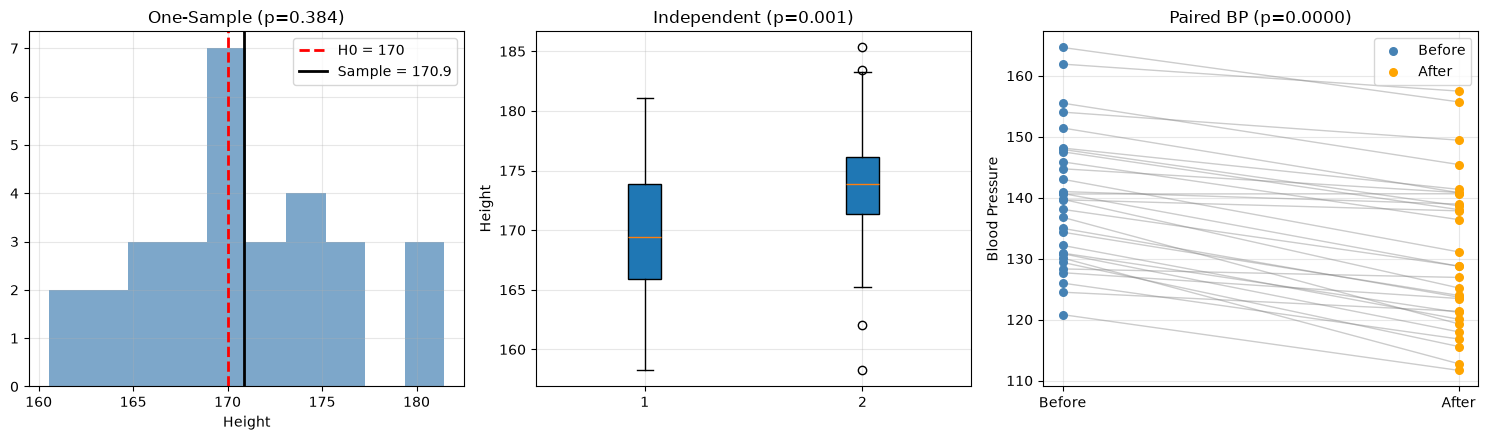

In [5]:
# Visualize all three designs
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Left plot: one-sample heights vs claimed 170
axes[0].hist(heights, bins=10, color="steelblue", alpha=0.7)
axes[0].axvline(170, color="red", linestyle="--", linewidth=2, label="H0 = 170")
axes[0].axvline(heights.mean(), color="black", linestyle="-", linewidth=2, label=f"Sample = {heights.mean():.1f}")
axes[0].set_title(f"One-Sample (p={p1:.3f})")
axes[0].set_xlabel("Height")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Middle plot: independent groups as boxplots
axes[1].boxplot([class_A, class_B], label=["Class A", "Class B"], patch_artist=True)
axes[1].set_title(f"Independent (p={p2:.3f})")
axes[1].set_ylabel("Height")
axes[1].grid(alpha=0.3)

# Right plot: paired lines, each person before -> after
for i in range(len(before)):
    axes[2].plot([0, 1], [before[i], after[i]], color="gray", alpha=0.4, linewidth=1)
axes[2].scatter([0]*len(before), before, color="steelblue", s=30, label="Before", zorder=5)
axes[2].scatter([1]*len(after), after, color="orange", s=30, label="After", zorder=5)
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Before", "After"])
axes[2].set_title(f"Paired BP (p={p3:.4f})")
axes[2].set_ylabel("Blood Pressure")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# Experiment - what if you wrongly use independent test on paired data?
# Correct paired test vs wrong independent test on the same before/after data
t_correct, p_correct = stats.ttest_rel(before, after)
t_wrong, p_wrong = stats.ttest_ind(before, after, equal_var=True)

print(f"Correct paired test: p={p_correct:.5f}")
print(f"Wrong independent test: p={p_wrong:.5f}")

# Try one-sided test because we only care if drug lowers pressure
_, p_one_sided = stats.ttest_rel(before, after, alternative="greater")
print(f"Paired one-sided (greater): p={p_one_sided:.5f}")

# Question: Why is the wrong p-value much bigger? What did it ignore?
# Question: When is a one-sided test allowed and when is it cheating?

Correct paired test: p=0.00000
Wrong independent test: p=0.00571
Paired one-sided (greater): p=0.00000
